# 02 · Recomendador híbrido (Reto 2)

**Objetivo de negocio:** recomendar a cada usuario de Nile Prime títulos que probablemente vea,
combinando el contenido de las películas (sinopsis, género, director, reparto) con el
comportamiento de los demás usuarios, y resolver el arranque en frío (usuarios o títulos
nuevos) con popularidad por grupo de edad y contenido.

**Objetivo técnico:** construir y evaluar un recomendador de contenido (TF-IDF por campos +
coseno), uno colaborativo ítem-ítem sobre feedback implícito y un **híbrido ponderado**
`α·CF + (1−α)·contenido`, frente a tres baselines (aleatorio, popularidad global, popularidad
por grupo de edad). Protocolo *leave-one-out* con **validación separada del test** (α y la
definición de interacción positiva se eligen en validación; el test se evalúa una vez), IC 95 %
por bootstrap sobre usuarios, tests pareados, prueba de permutación, cobertura, diversidad,
costo operativo y análisis de fallos.

**Hipótesis a contrastar, no a confirmar.** El notebook 00 (sección 9) mostró que el histórico
no contiene estructura de preferencias (edad × título: χ² = 1.928,8 con gl = 1.996, p = 0,86;
los pares de títulos de un mismo usuario comparten género el 65,92 % de las veces frente a
65,94 % barajando, p = 0,75). Por eso se espera que **todos los métodos rindan ≈ azar**
(HitRate@10 ≈ 10/999 ≈ 1 %). Aquí se mide, y para comprobar que el método *sí* recupera señal
cuando existe, se repite el mismo pipeline sobre datos sintéticos con preferencias sembradas
(sección 11).

**Nota sobre las cifras:** las cifras citadas en el texto corresponden a la **ejecución
completa** (`full`). Con `NP_FAST=1` (1.000 usuarios, menos remuestreos y réplicas, dos valores
de `p_pref`) varían y valen las salidas de las celdas.

## Requisitos

- **Local:** Python ≥ 3.11 y `pip install -r requirements.txt` (o `python harness/init.py --install`, que crea el `.venv`).
- **Colab:** la celda de instalación de más abajo ejecuta `%pip install -q paquete==versión` **solo para lo que falte** (versión fijada). No se reinstalan `numpy`, `pandas`, `scikit-learn`, `matplotlib` ni `torch`: Colab ya los trae y cambiarlos obliga a reiniciar el entorno, lo que rompe «Ejecutar todo». Si no hay `data/raw`, la primera celda clona el repositorio público (o usa `NilePrime_AliGuerrero_codigo.zip` en `/content`).
- **Librerías de este notebook (versión de `requirements.txt`):** `pandas==2.3.3`, `numpy==2.3.5`, `scikit-learn==1.7.2`, `scipy==1.18.1`, `matplotlib==3.10.6`.

In [1]:
# Entorno: Colab o local y raíz del proyecto sin rutas absolutas (la instalación va en la celda siguiente).
REPO_URL = "https://github.com/aliguerreroj/nile-prime-ia.git"  # repositorio público con código y datos
ZIP_NAME = "NilePrime_AliGuerrero_codigo.zip"  # alternativa sin GitHub: subirlo a /content

import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
FAST = os.environ.get("NP_FAST") == "1"
SEED = 42

# Raíz = primera carpeta (cwd o sus padres) que contiene data/raw.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw").is_dir()),
    None,
)
if RAIZ is None and EN_COLAB:
    # Colab: (a) zip en /content, (b) si no hay zip, git clone del repositorio público.
    import subprocess
    import zipfile

    _base = Path("/content")

    def _buscar_raiz():
        """Rutas directas primero; rglob solo como último recurso (sin recorrer /content/drive)."""
        for _d in (_base / "nile-prime-ia", _base / "NilePrime_AliGuerrero_codigo", _base):
            if (_d / "data" / "raw").is_dir():
                return _d
        for _sub in sorted(_base.iterdir()):
            if _sub.is_dir() and _sub.name not in ("drive", "sample_data"):
                for _raw in sorted(_sub.rglob("raw")):
                    if _raw.parent.name == "data" and _raw.is_dir():
                        return _raw.parent.parent
        return None

    for _z in sorted(_base.glob("NilePrime*codigo*.zip")) or sorted(_base.glob("*.zip")):
        with zipfile.ZipFile(_z) as _f:
            if any("data/raw/" in n for n in _f.namelist()):
                _f.extractall(_base)
                break
    RAIZ = _buscar_raiz()
    if RAIZ is None:
        try:
            _git = subprocess.run(["git", "clone", "--depth", "1", REPO_URL], cwd=_base,
                                  check=False, capture_output=True, text=True)
            _err = (_git.stderr or _git.stdout or "").strip().splitlines()
        except OSError as _e:
            _err = [str(_e)]
        RAIZ = _buscar_raiz()
        if RAIZ is None:
            raise RuntimeError(
                "No se pudo obtener el proyecto en Colab. Opción 1: comprueba la conexión a "
                "internet y vuelve a ejecutar (se clona " + REPO_URL + "). Opción 2: sube "
                + ZIP_NAME + " a /content y vuelve a ejecutar. Último error de git: "
                + (_err[-1] if _err else "sin salida")
            )
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra data/raw: ejecuta el notebook desde la carpeta del proyecto o una subcarpeta."
    )
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

In [2]:
# Instalación de dependencias (solo Colab, solo lo que falte; en local no instala nada).
# Colab ya trae todo lo demás; scipy se comprueba por si acaso.
import importlib.util

# paquete pip -> (módulo importable, versión fijada en requirements.txt)
_REQUISITOS = {"scipy": ("scipy", "1.18.1")}
_faltan = [f"{p}=={v}" for p, (m, v) in _REQUISITOS.items() if importlib.util.find_spec(m) is None]
if EN_COLAB and _faltan:
    for _spec in _faltan:
        # Equivalente a la magia:  %pip install -q scipy==1.18.1
        # (se usa run_line_magic porque jupytext no descomenta magias dentro de un bloque `if`).
        get_ipython().run_line_magic("pip", f"install -q {_spec}")  # noqa: F821
    print("Instalado:", ", ".join(_faltan))
else:
    print("Nada que instalar" + ("" if EN_COLAB else " (entorno local: usa requirements.txt)"))

Nada que instalar (entorno local: usa requirements.txt)


In [3]:
# Imports, semilla y configuración común.
import json
import pickle
import time
import warnings
from contextlib import contextmanager

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

from src import data, plots, synthetic as syn
from src import recommender as rec

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
np.random.seed(SEED)
plots.set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
MODO = "fast" if FAST else "full"
K = 10                                   # longitud de la lista (justificación en la sección 5)
N_BOOT = 200 if FAST else 1000           # remuestreos bootstrap (por usuario)
N_PERM = 200 if FAST else 1000           # réplicas de la prueba de permutación
N_SEM = 2 if FAST else 5                 # semillas por dosis en la señal sembrada
N_BOOT_SEM = 100 if FAST else 200        # bootstrap por semilla (el IC reportado es entre semillas)
DOSIS = [0.0, 0.9] if FAST else [0.0, 0.3, 0.6, 0.9]   # intensidades de señal sembrada
REJILLA = rec.REJILLA_ALPHA              # α ∈ {0, 0,1, …, 1}
print(f"Modo: {MODO} | SEED = {SEED} | Colab: {EN_COLAB} | K = {K} | bootstrap = {N_BOOT} | "
      f"permutaciones = {N_PERM}")
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__}")

TIEMPOS: dict[str, float] = {}  # segundos por sección (objetivo: < 10 min en total)


@contextmanager
def seccion(nombre: str):
    """Mide el tiempo de pared de una sección y lo guarda en ``TIEMPOS``."""
    t0 = time.perf_counter()
    yield
    TIEMPOS[nombre] = round(time.perf_counter() - t0, 1)


def fmt(m: dict, d: int = 4) -> str:
    """Formatea ``{"valor", "ic95"}`` como ``0.0110 [0.0091, 0.0130]``."""
    lo, hi = m["ic95"]
    return f"{m['valor']:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"

Modo: full | SEED = 42 | Colab: False | K = 10 | bootstrap = 1000 | permutaciones = 1000
numpy 2.3.5 | pandas 2.3.3 | scipy 1.18.1 | scikit-learn 1.7.2


## 1. Datos y diseño del experimento

**Qué:** catálogo de 999 títulos únicos (`load_metadata(titulos_unicos=True)`) e interacciones
usuario–título sin duplicados (`load_interactions(sin_duplicados=True)`): 100.623 filas,
10.000 usuarios, `Watched_to_End` (bool) y `Age_Group` (uno por usuario).

**Feedback implícito.** No hay valoraciones: solo hay "vio / vio hasta el final". Se compararán
dos definiciones de interacción positiva: **(a)** cualquier película vista y **(b)** solo
`Watched_to_End = True`. No existe marca de tiempo ni columna de tiempo visto (el PDF del caso
las menciona; no vienen en los datos), así que no hay partición temporal posible.

**Limitaciones de los datos que condicionan el diseño:**
* "Drishyam" son dos películas (2013 y 2015) con el mismo título; `interacciones.csv` solo trae
  el título, así que las interacciones de ambas se asignan a una sola fila del catálogo único
  (≈ 221 frente a ≈ 100 ± 10 del resto). **Corrección (popularidad):** el recuento de
  popularidad de un título colisionado se divide entre el nº de películas que lo comparten en los
  metadatos crudos (1.000 filas), `rec.pesos_por_colision`. La colisión se detecta en los datos
  (títulos repetidos), no por nombre, y solo afecta a los recuentos de popularidad (global, por
  edad y arranque en frío); CF y contenido no se tocan. Alternativa descartada: excluir el título
  del ranking de popularidad, que descartaría información real (≈ 110 vistas por película).
* Popularidad casi uniforme (≈ 100 ± 10 interacciones por título) y sin estructura de
  preferencias (notebook 00, §9). Un recomendador no puede aprender lo que no está en los datos.

**Protocolo (resumen).**
1. *Elegibles:* usuarios con ≥ 3 vistas completas. Por usuario se retiran **dos** vistas completas
   al azar (positivas bajo (a) y bajo (b)): una a **validación** y otra a **test**. El resto es train.
2. *Validación:* elige la definición de positivo y α. *Test:* se evalúa **una sola vez**, con la
   configuración ya fijada, ajustando los modelos con train + el ítem de validación.
3. *Ranking:* sobre todos los ítems no vistos; K = 10; métricas por usuario y bootstrap sobre usuarios.

**Sobre la corrección de la colisión de títulos:** se decidió por la naturaleza del dato (un
título repetido en el catálogo crudo), no por las métricas. El test ya se había evaluado una
vez con la popularidad sin corregir; por eso se reportan los dos valores (antes y después) en
la sección 9 y en `recomendador.json`. La corrección solo afecta a los baselines de
popularidad con datos reales: en los datos sintéticos de la sección 11 no hay títulos
repetidos y no se aplica.

In [4]:
with seccion("1_datos"):
    cat = data.load_metadata(titulos_unicos=True)
    inter = data.load_interactions(sin_duplicados=True)
    N_ITEMS = len(cat)
    assert set(inter["Series_Title"]) <= set(cat["Series_Title"])
    # Colisión de títulos: detectada en los metadatos crudos (1.000 filas) y no por nombre.
    cat_crudo = data.load_metadata()
    PESOS_POP = rec.pesos_por_colision(cat, cat_crudo)

print(f"Catálogo: {N_ITEMS} títulos | interacciones: {len(inter):,} | "
      f"usuarios: {inter['User_ID'].nunique():,}")
print(f"Watched_to_End = True: {inter['Watched_to_End'].mean():.2%}")
print(inter.groupby("User_ID").size().describe()[["min", "50%", "max"]].to_string())
print("Usuarios por grupo de edad:")
print(inter.drop_duplicates("User_ID")["Age_Group"].value_counts().to_string())
pop = inter.groupby("Series_Title").size()
print(f"Interacciones por título: media {pop.mean():.1f}, desv. {pop.std():.1f}, "
      f"mín {pop.min()}, máx {pop.max()}")
colisionados = cat.loc[PESOS_POP < 1, "Series_Title"].tolist()
print(f"Títulos repetidos en los metadatos crudos ({len(cat_crudo)} filas): {colisionados} "
      f"-> pesos de popularidad {PESOS_POP[PESOS_POP < 1].tolist()}")
for t_ in colisionados:
    print(f"  «{t_}»: {pop[t_]} interacciones asignadas a una sola fila "
          f"({pop[t_] * PESOS_POP[cat['Series_Title'] == t_][0]:.1f} tras repartir)")

Catálogo: 999 títulos | interacciones: 100,623 | usuarios: 10,000
Watched_to_End = True: 89.75%
min    1.0000
50%   10.0000
max   24.0000
Usuarios por grupo de edad:
Age_Group
youth      3363
adults     3356
seniors    3281
Interacciones por título: media 100.7, desv. 11.0, mín 71, máx 221
Títulos repetidos en los metadatos crudos (1000 filas): ['Drishyam'] -> pesos de popularidad [0.5]
  «Drishyam»: 221 interacciones asignadas a una sola fila (110.5 tras repartir)


**Conclusión técnica.** El conjunto es una matriz usuario × ítem muy dispersa (≈ 1 % de densidad)
con popularidad plana; sin tiempos ni valoraciones, el protocolo posible es un
*leave-one-out* aleatorio con feedback implícito.

**Implicación de negocio.** Con estos datos solo se puede evaluar si el recomendador adivina un
título ya visto, no si el usuario lo habría visto "después".

## 2. Partición leave-one-out con validación, sin fuga

**Qué:** `particionar_loo` retira, por usuario elegible, una vista completa a validación y otra a
test, elegidas con `SEED`. **Por qué dos:** así ambos retenidos son positivos bajo (a) y (b) y la
comparación de definiciones se hace sobre los mismos objetivos.

**Anti-fuga:** `comprobar_sin_fuga` verifica que ningún par (usuario, título) retenido esté en
train, que validación y test no compartan pares y que `val`/`test` estén alineados con los
elegibles. Los usuarios no elegibles permanecen íntegros en train (aportan a CF y popularidad).
**Limitación:** sin marca de tiempo el retenido es aleatorio, no "el último", y el modelo puede
usar vistas "futuras" del propio usuario como contexto, lo que hace la tarea más fácil de lo que
sería en producción.

In [5]:
with seccion("2_particion"):
    part = rec.particionar_loo(inter, seed=SEED, min_completas=3)
    rec.comprobar_sin_fuga(part)  # lanza AssertionError si hubiera fuga

USUARIOS = part["elegibles"]
n_el = len(USUARIOS)
print(f"Usuarios elegibles (≥ 3 vistas completas): {n_el:,} de {inter['User_ID'].nunique():,}")
print(f"Filas: train {len(part['train']):,} | validación {len(part['val']):,} | "
      f"test {len(part['test']):,}")
print("Sin fuga: ningún par (usuario, título) retenido está en train ni se repite entre val y test")

Usuarios elegibles (≥ 3 vistas completas): 9,950 de 10,000
Filas: train 80,723 | validación 9,950 | test 9,950
Sin fuga: ningún par (usuario, título) retenido está en train ni se repite entre val y test


**Conclusión técnica.** Partición reproducible, con un objetivo de validación y uno de test por
usuario elegible, y con la ausencia de fuga verificada por *assert*.

**Implicación de negocio.** Las cifras de test no se han usado para decidir nada: son una
estimación honesta de cómo rendiría el recomendador sobre vistas que no conoce.

## 3. Modelos

**Contenido.** TF-IDF *por campo* y concatenación ponderada: `Overview` (palabras, sin
*stopwords*, `sublinear_tf`), `Genre` (cada género es un término), `Director` (nombre completo
como término) y `Stars` (Star1–Star4 como términos). Cada campo se normaliza L2 y se escala
por `√peso`, de modo que el producto escalar de dos ítems es la **suma ponderada de las
similitudes coseno por campo**. Pesos fijados a priori (no ajustados): Overview 0,35,
Genre 0,30, Director 0,15, Stars 0,20 (Overview es corto y ruidoso, mediana de 24 palabras; Genre
es el más denso; 547 directores distintos y 2.705 actores dan señal rala pero muy específica).
Los vectorizadores solo usan metadatos del catálogo: no hay etiquetas ni interacciones, así que
no introducen fuga. Se descartaron *embeddings* de frases (dependencia extra y sinopsis de ~24
palabras: ganancia dudosa).

**Colaborativo.** kNN ítem-ítem por coseno sobre la matriz binaria usuario × ítem (dispersa); la
puntuación de un candidato es la suma de similitudes con los ítems positivos del usuario. Se
elige kNN ítem-ítem y no factorización (ALS/SVD) porque el catálogo es pequeño (la matriz de
similitudes 999 × 999 ocupa 8 MB), no hay librerías de recomendación disponibles, no requiere
hiperparámetros de rango/regularización y es interpretable. Trade-off: no generaliza por
factores latentes y es sensible a la dispersión.

**Híbrido.** `score = α·z(CF) + (1−α)·z(contenido)`, con cada componente normalizado por
usuario (z-score sobre sus candidatos no vistos): ambos quedan en la misma escala y α es un
peso relativo interpretable. α = 0 es contenido puro y α = 1 colaborativo puro.

**Baselines.** Aleatorio, popularidad global y **popularidad por grupo de edad** (la edad como
señal, y recurso de arranque en frío). **Arranque en frío:** usuario sin historial →
popularidad de su grupo (global si no hay grupo); ítem sin interacciones → solo contenido.

In [6]:
with seccion("3_modelos"):
    t0 = time.perf_counter()
    SIM = rec.similitud_contenido(cat)
    t_sim = time.perf_counter() - t0

print(f"Similitud de contenido: {SIM.shape}, rango [{SIM.min():.2f}, {SIM.max():.2f}], "
      f"similitud media entre pares distintos {SIM.sum() / (N_ITEMS * (N_ITEMS - 1)):.4f} "
      f"({t_sim:.2f} s)")
print("Pesos por campo:", rec.PESOS_CAMPOS)
print("Rejilla de α:", list(REJILLA))

Similitud de contenido: (999, 999), rango [0.00, 0.73], similitud media entre pares distintos 0.0590 (0.04 s)


Pesos por campo: {'Overview': 0.35, 'Genre': 0.3, 'Director': 0.15, 'Stars': 0.2}
Rejilla de α: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(1.0)]


**Conclusión técnica.** La similitud de contenido es una matriz densa 999 × 999 con
autosimilitud anulada; se calcula una vez (solo depende del catálogo) y se comparte entre
modelos. El CF se reconstruye en cada ajuste porque depende de las interacciones de train.

**Implicación de negocio.** El mismo motor sirve para el catálogo actual y para títulos nuevos:
basta con sus metadatos.

## 4. Validación: definición de positivo y peso α

**Qué:** para cada definición de interacción positiva —(a) `cualquiera`, (b) `completa`— se
evalúa el híbrido en toda la rejilla de α sobre los **objetivos de validación** (NDCG@10 y
HitRate@10), con modelos ajustados **solo con train**. El test no interviene.

**Regla de decisión fijada de antemano** (para no premiar el ruido): el α de cada definición es el
argmax del NDCG@10 de validación **solo si** supera de forma significativa (Wilcoxon pareado por
usuario, p < 0,05) a α = 0,5 (neutro); si no, α = 0,5. La definición (b) se elige solo si su
híbrido supera significativamente al de (a); en otro caso se mantiene (a), la más simple (usa
todos los datos). Con 21 valores de α × 2 definiciones, tomar el máximo sin esta puerta
produciría el sesgo del ganador (*winner's curse*) sobre la validación.

In [7]:
with seccion("4_validacion"):
    SEL = rec.seleccionar_configuracion(cat, part["train"], part["val"], USUARIOS, SIM, K,
                                        REJILLA, SEED)

tabla_val = pd.concat([pd.DataFrame(v) for v in SEL["tablas"].values()])
print("NDCG@10 de validación (híbrido) por α y definición:")
print(tabla_val.pivot(index="alpha", columns="definicion", values="ndcg").to_string())
print("\nHitRate@10 de validación (híbrido) por α y definición:")
print(tabla_val.pivot(index="alpha", columns="definicion", values="hit").to_string())
print("\nα máximo y p (Wilcoxon) frente a α = 0,5:")
for d, v in SEL["p_alpha"].items():
    print(f"  {d:10s} α_max = {v['alpha_max']:.1f}  p = {v['p_vs_0_5']:.3f}  "
          f"-> α usado = {SEL['alpha_por_definicion'][d]:.1f}")
dd = SEL["dif_definiciones"]
print(f"\ncompleta − cualquiera (NDCG@10, validación): {dd['ndcg_completa_menos_cualquiera']:+.5f} "
      f"(p = {dd['p_wilcoxon']:.3f})")
CFG = {"definicion": SEL["definicion"], "alpha": SEL["alpha"]}
print(f"\nConfiguración elegida en validación: positivo = {CFG['definicion']!r}, "
      f"α = {CFG['alpha']}")

NDCG@10 de validación (híbrido) por α y definición:
definicion  completa  cualquiera
alpha                           
0.0000        0.0042      0.0044
0.1000        0.0044      0.0046
0.2000        0.0045      0.0043
0.3000        0.0043      0.0046
0.4000        0.0044      0.0045
0.5000        0.0046      0.0042
0.6000        0.0046      0.0041
0.7000        0.0045      0.0044
0.8000        0.0047      0.0044
0.9000        0.0048      0.0046
1.0000        0.0048      0.0048

HitRate@10 de validación (híbrido) por α y definición:
definicion  completa  cualquiera
alpha                           
0.0000        0.0099      0.0093
0.1000        0.0102      0.0097
0.2000        0.0104      0.0089
0.3000        0.0096      0.0095
0.4000        0.0096      0.0099
0.5000        0.0102      0.0097
0.6000        0.0099      0.0093
0.7000        0.0097      0.0095
0.8000        0.0096      0.0093
0.9000        0.0099      0.0099
1.0000        0.0101      0.0107

α máximo y p (Wilcoxon) frente a 

**Conclusión técnica.** En validación el NDCG@10 del híbrido oscila entre 0,0041 y 0,0048 y el HitRate@10 entre 0,0089 y 0,0107 en toda la rejilla de α y con ambas definiciones, sin tendencia: es el rango esperable por azar (HitRate ≈ 0,0101). El máximo está en α = 1 para las dos definiciones, pero no supera a α = 0,5 (Wilcoxon p = 0,435 con (a) y p = 0,891 con (b)); la definición (b) tampoco supera a la (a) (ΔNDCG@10 = +0,0004, p = 0,463). Por la regla fijada de antemano se elige **(a) «cualquier película vista» con α = 0,5**. La elección es, por tanto, **arbitraria**: los datos no la respaldan y no debe leerse como que (a) o α = 0,5 sean mejores. Que `Watched_to_End` no aporte nada es coherente con el notebook 00.

**Implicación de negocio.** Con estos datos no hay una forma «mejor» de definir un interés ni de mezclar contenido y comportamiento; se usa la opción más simple.

## 5. Evaluación en test (una sola vez)

**Qué:** se ajustan los seis recomendadores con la configuración elegida sobre train + ítem de
validación y se rankean todos los ítems no vistos de cada usuario elegible. Métricas por usuario
(Precision, Recall, NDCG y HitRate @10) e **IC 95 % por bootstrap sobre usuarios**
(remuestreos con reemplazo de los usuarios; los mismos remuestreos para todos los
recomendadores, por lo que las diferencias son pareadas).

**Por qué K = 10:** es la longitud de una fila de carrusel típica en una pantalla de inicio de
streaming; es una decisión de producto, no se ajustó con los datos. Los empates de puntuación se
rompen con un desempate aleatorio reproducible.

**Aviso de lectura.** Con **un solo ítem retenido** por usuario: Recall@10 = HitRate@10 y
Precision@10 = HitRate@10 / 10. Las cuatro métricas no son evidencia independiente; el
contenido informativo está en HitRate@10 y NDCG@10 (este último premia posiciones altas).
**Azar teórico:** un ranking aleatorio acierta con probabilidad K / N_candidatos ≈ 10 / 990.

In [8]:
with seccion("5_test"):
    TE = rec.evaluar_test(cat, part, CFG, SIM, K, SEED, guardar_rangos=True,
                          pesos_popularidad=PESOS_POP)
    RES, MODELOS, OBJ = TE["resultados"], TE["modelos"], TE["objetivo"]
    IC = rec.ic_todos(RES, N_BOOT, SEED)
    AZAR = rec.azar_teorico(RES["Híbrido"]["n_candidatos"], K)

NOMBRES = list(RES)
filas = []
for n in NOMBRES:
    filas.append({"recomendador": n,
                  "HitRate@10": fmt(IC[n]["hit"]), "NDCG@10": fmt(IC[n]["ndcg"]),
                  "Precision@10": fmt(IC[n]["precision"], 5), "Recall@10": fmt(IC[n]["recall"])})
print(f"Test: {n_el:,} usuarios | azar teórico: HitRate@10 = {AZAR['hit']:.4f}, "
      f"NDCG@10 = {AZAR['ndcg']:.4f}")
print(pd.DataFrame(filas).to_string(index=False))
med = {n: float(np.median(RES[n]["rango_objetivo"])) for n in NOMBRES}
print("\nRango mediano del ítem retenido (esperado bajo azar ≈ N_candidatos / 2 = "
      f"{np.median(RES['Híbrido']['n_candidatos']) / 2:.0f}):", {k_: round(v) for k_, v in med.items()})

Test: 9,950 usuarios | azar teórico: HitRate@10 = 0.0101, NDCG@10 = 0.0046
        recomendador              HitRate@10                 NDCG@10               Precision@10               Recall@10
           Aleatorio 0.0106 [0.0086, 0.0126] 0.0045 [0.0036, 0.0055] 0.00106 [0.00086, 0.00126] 0.0106 [0.0086, 0.0126]
  Popularidad global 0.0099 [0.0081, 0.0121] 0.0046 [0.0036, 0.0057] 0.00099 [0.00081, 0.00121] 0.0099 [0.0081, 0.0121]
Popularidad por edad 0.0091 [0.0074, 0.0110] 0.0037 [0.0030, 0.0045] 0.00091 [0.00074, 0.00110] 0.0091 [0.0074, 0.0110]
           Contenido 0.0103 [0.0083, 0.0123] 0.0047 [0.0038, 0.0058] 0.00103 [0.00083, 0.00123] 0.0103 [0.0083, 0.0123]
        Colaborativo 0.0114 [0.0092, 0.0135] 0.0050 [0.0040, 0.0061] 0.00114 [0.00092, 0.00135] 0.0114 [0.0092, 0.0135]
             Híbrido 0.0110 [0.0089, 0.0130] 0.0056 [0.0044, 0.0068] 0.00110 [0.00089, 0.00130] 0.0110 [0.0089, 0.0130]

Rango mediano del ítem retenido (esperado bajo azar ≈ N_candidatos / 2 = 495): {'Ale

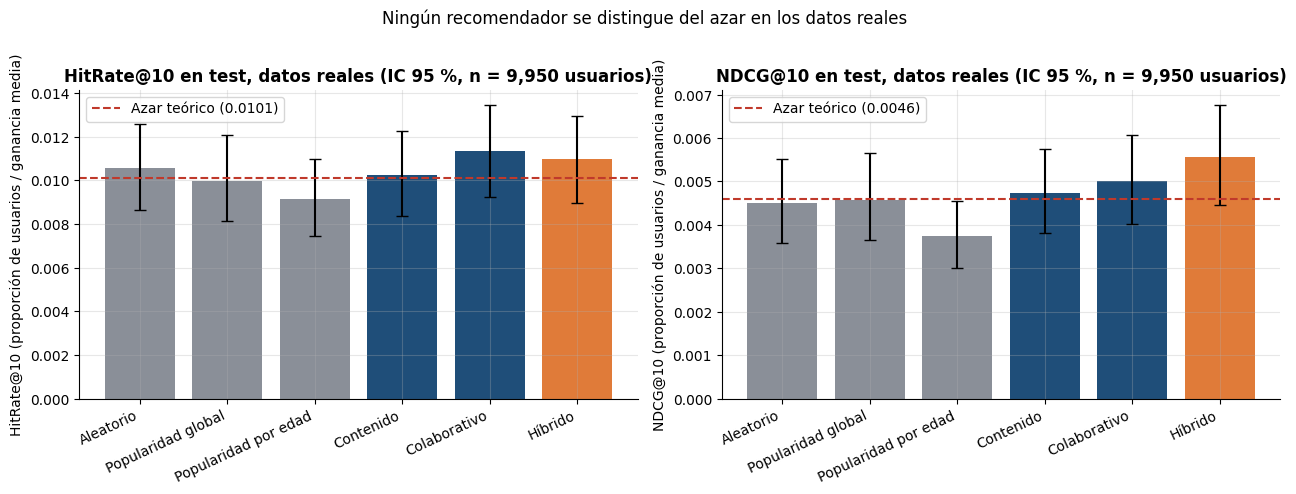

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colores = {"Aleatorio": plots.PALETA["neutro"], "Popularidad global": plots.PALETA["neutro"],
           "Popularidad por edad": plots.PALETA["neutro"], "Contenido": plots.PALETA["principal"],
           "Colaborativo": plots.PALETA["principal"], "Híbrido": plots.PALETA["enfasis"]}
for ax, met, titulo, azar in (
    (axes[0], "hit", "HitRate@10", AZAR["hit"]), (axes[1], "ndcg", "NDCG@10", AZAR["ndcg"])
):
    v = np.array([IC[n][met]["valor"] for n in NOMBRES])
    lo = np.array([IC[n][met]["ic95"][0] for n in NOMBRES])
    hi = np.array([IC[n][met]["ic95"][1] for n in NOMBRES])
    ax.bar(range(len(NOMBRES)), v, yerr=[v - lo, hi - v], capsize=4,
           color=[colores[n] for n in NOMBRES])
    ax.axhline(azar, color=plots.PALETA["referencia"], ls="--", lw=1.5,
               label=f"Azar teórico ({azar:.4f})")
    ax.set_xticks(range(len(NOMBRES)))
    ax.set_xticklabels(NOMBRES, rotation=25, ha="right")
    ax.set_ylabel(f"{titulo} (proporción de usuarios / ganancia media)")
    ax.set_title(f"{titulo} en test, datos reales (IC 95 %, n = {n_el:,} usuarios)")
    ax.legend()
fig.suptitle("Ningún recomendador se distingue del azar en los datos reales", y=1.02)
fig.tight_layout()
plots.save_fig(fig, "02_comparacion_recomendadores")
plt.show()

**Conclusión técnica.** Con 9.950 usuarios y un azar teórico de HitRate@10 = 0,0101 y NDCG@10 = 0,0046, **ningún recomendador se distingue del azar**: el híbrido obtiene HitRate@10 = 0,0110 [0,0089; 0,0130] y NDCG@10 = 0,0056 [0,0044; 0,0068]; la popularidad global (con la corrección de «Drishyam», sección 1), 0,0099 [0,0081; 0,0121] y 0,0046 [0,0036; 0,0057]; la popularidad por edad, 0,0091 [0,0074; 0,0110] y 0,0037 [0,0030; 0,0045] (algo por debajo del azar en NDCG@10, 0,0046); contenido 0,0103 y colaborativo 0,0114. Todos los IC de HitRate@10 contienen el azar y el rango mediano del ítem retenido (491-503 entre ≈ 990 candidatos) coincide con la mediana de un orden aleatorio (≈ 495). Precision@10 = 0,0011 y Recall@10 = 0,0110 (con un solo retenido son reescalados de HitRate@10, no evidencia independiente). Es la cifra prevista por la ausencia de estructura medida en el notebook 00 (≈ 1 %); el modelo no está roto (sección 11), pero tampoco hay mejora que reportar.

**Implicación de negocio.** Con el histórico actual ningún recomendador, ni el más sofisticado, acierta más que sortear títulos: invertir en afinar este modelo no tiene retorno hasta que haya datos con preferencias.

## 6. ¿Supera el híbrido a la popularidad? Tests pareados por usuario

**Qué:** comparación pareada por usuario del híbrido con la popularidad global (baseline
principal), la popularidad por edad y el azar. Para **HitRate@10**: diferencia con IC 95 %
bootstrap pareado y **McNemar exacto** sobre los desacuerdos (aciertos de uno y fallo del otro).
Para **NDCG@10**: diferencia con IC y **Wilcoxon de rangos con signo**. "Supera" significa IC 95 %
de la diferencia por encima de 0 **y** p < 0,05; si no, "sin diferencia significativa". Son
varias comparaciones (3 por métrica); no se aplica corrección múltiple porque ninguna
resulta significativa (corregir solo restaría significancia).

In [10]:
with seccion("6_pareados"):
    PAR = {b: rec.comparar_pareado(RES["Híbrido"]["metricas"], RES[b]["metricas"], N_BOOT, SEED)
           for b in ("Popularidad global", "Popularidad por edad", "Aleatorio")}
filas = []
for b, r in PAR.items():
    filas.append({
        "Híbrido − " + b: "",
        "ΔHitRate@10 [IC95]": f"{r['hit']['diferencia']:+.4f} "
                              f"[{r['hit']['ic95'][0]:+.4f}, {r['hit']['ic95'][1]:+.4f}]",
        "p McNemar": f"{r['hit']['p_mcnemar']:.3f}",
        "ΔNDCG@10 [IC95]": f"{r['ndcg']['diferencia']:+.4f} "
                           f"[{r['ndcg']['ic95'][0]:+.4f}, {r['ndcg']['ic95'][1]:+.4f}]",
        "p Wilcoxon": f"{r['ndcg']['p_wilcoxon']:.3f}",
        "¿híbrido mejor?": "sí" if (r["hit"]["a_mejor"] or r["ndcg"]["a_mejor"]) else "no",
    })
for f in filas:
    print(pd.DataFrame([f]).to_string(index=False))
r = PAR["Popularidad global"]["hit"]
print(f"\nVs popularidad global: híbrido acierta y popularidad falla en {r['a_acierta_b_falla']} "
      f"usuarios; al revés en {r['a_falla_b_acierta']}.")

Híbrido − Popularidad global         ΔHitRate@10 [IC95] p McNemar            ΔNDCG@10 [IC95] p Wilcoxon ¿híbrido mejor?
                             +0.0010 [-0.0019, +0.0039]     0.531 +0.0010 [-0.0005, +0.0026]      0.225              no
Híbrido − Popularidad por edad         ΔHitRate@10 [IC95] p McNemar            ΔNDCG@10 [IC95] p Wilcoxon ¿híbrido mejor?
                               +0.0018 [-0.0008, +0.0045]     0.227 +0.0018 [+0.0004, +0.0032]      0.023              sí
Híbrido − Aleatorio         ΔHitRate@10 [IC95] p McNemar            ΔNDCG@10 [IC95] p Wilcoxon ¿híbrido mejor?
                    +0.0004 [-0.0024, +0.0032]     0.835 +0.0011 [-0.0004, +0.0026]      0.119              no

Vs popularidad global: híbrido acierta y popularidad falla en 108 usuarios; al revés en 98.


**Conclusión técnica.** **El híbrido no supera a la popularidad global**: ΔHitRate@10 = +0,0010 [−0,0019; +0,0039] (McNemar p = 0,531; en 108 usuarios acierta solo el híbrido y en 98 solo la popularidad) y ΔNDCG@10 = +0,0010 [−0,0005; +0,0026] (Wilcoxon p = 0,225). Frente al azar tampoco hay diferencia (ΔHitRate@10 = +0,0004, p = 0,835; ΔNDCG@10 = +0,0011 [−0,0004; +0,0026], p = 0,119). Frente a la popularidad por edad, ΔHitRate@10 = +0,0018 [−0,0008; +0,0045] (p = 0,227) y ΔNDCG@10 = +0,0018 [+0,0004; +0,0032] con p = 0,023, nominalmente significativo: es 1 de 6 contrastes (umbral de Bonferroni 0,008) y la popularidad por edad queda por debajo del azar en NDCG@10 (0,0037 frente a 0,0046), de modo que refleja un baseline pobre más que mérito del híbrido; se trata como falso positivo probable. Sin diferencia robusta en ningún contraste.

**Implicación de negocio.** El híbrido no es mejor que enseñar a todos lo más visto; no hay base para vender una mejora de recomendación con el histórico actual.

## 7. Prueba de permutación: ¿hay señal usuario–ítem?

**Qué:** el bootstrap dice cuánto incierta es cada métrica, pero no si existe señal. La prueba de
permutación responde a esa pregunta: bajo H0 el ítem retenido **no depende del usuario**. Se
simula barajando entre usuarios el ítem retenido de test (esto conserva la distribución de
popularidad de los retenidos y rompe el vínculo usuario–ítem) y se recalcula HitRate@10 y NDCG@10
de cada recomendador. El p-valor es empírico, de una cola, con corrección +1:
`(1 + #{nulo ≥ observado}) / (R + 1)`. Los pares barajados cuyo ítem ya estaba en el historial del
usuario se descartan (<1 %). Es eficiente porque la matriz usuarios × ítems de rangos se calcula una
sola vez y cada réplica es un *gather*. Se compara además con el valor teórico K / N.

In [11]:
with seccion("7_permutacion"):
    PERM = {n: rec.prueba_permutacion(RES[n]["rangos"], OBJ, K, N_PERM, SEED) for n in NOMBRES}
filas = []
for n, p in PERM.items():
    filas.append({
        "recomendador": n, "HitRate obs.": p["hit_obs"], "nulo (media)": p["hit_nulo_media"],
        "nulo (p95)": p["hit_nulo_p95"], "p HitRate": p["p_hit"],
        "NDCG obs.": p["ndcg_obs"], "nulo NDCG": p["ndcg_nulo_media"], "p NDCG": p["p_ndcg"],
    })
print(f"Réplicas: {N_PERM} | azar teórico HitRate@10 = {AZAR['hit']:.4f}, "
      f"NDCG@10 = {AZAR['ndcg']:.4f} | pares válidos tras barajar: "
      f"{PERM['Híbrido']['fraccion_pares_validos']:.3%}")
print(pd.DataFrame(filas).to_string(index=False))

Réplicas: 1000 | azar teórico HitRate@10 = 0.0101, NDCG@10 = 0.0046 | pares válidos tras barajar: 99.088%
        recomendador  HitRate obs.  nulo (media)  nulo (p95)  p HitRate  NDCG obs.  nulo NDCG  p NDCG
           Aleatorio        0.0106        0.0101      0.0117     0.3007     0.0045     0.0046  0.5584
  Popularidad global        0.0099        0.0100      0.0102     0.4436     0.0046     0.0046  0.5974
Popularidad por edad        0.0091        0.0102      0.0116     0.8931     0.0037     0.0046  0.9900
           Contenido        0.0103        0.0100      0.0117     0.4036     0.0047     0.0046  0.3606
        Colaborativo        0.0114        0.0102      0.0118     0.1169     0.0050     0.0046  0.2298
             Híbrido        0.0110        0.0101      0.0118     0.1908     0.0056     0.0046  0.0210


**Conclusión técnica.** Los p-valores de HitRate@10 van de 0,12 a 0,89 en los seis recomendadores: **no hay evidencia de señal usuario-ítem** (el HitRate observado del híbrido, 0,0110, queda dentro de la distribución nula, con media 0,0101 = K/N y percentil 95 en 0,0118). Una excepción nominal: NDCG@10 del híbrido, 0,0056 frente a 0,0046 nulo, p = 0,021; es 1 de 12 contrastes (6 recomendadores × 2 métricas; umbral de Bonferroni 0,004), con HitRate@10 en p = 0,19 y sin diferencia frente a azar ni popularidad en la sección 6 (p = 0,119 y 0,225), por lo que se trata como falso positivo probable y no como señal. Tras corregir la colisión de «Drishyam», la popularidad global ya no se aparta de su nulo (HitRate@10 observado 0,0099 frente a 0,0100; NDCG@10 0,0046 frente a 0,0046): el pequeño sesgo de popularidad que se veía antes (nulo de 0,0109, por el título inflado) desaparece. El resultado es consistente con la hipótesis de datos sin preferencias.

**Implicación de negocio.** La prueba de permutación confirma que el histórico no contiene gustos individuales que un recomendador pueda aprovechar.

## 8. Cobertura de catálogo y diversidad intra-lista

**Qué:** *cobertura* = fracción del catálogo que aparece en alguna lista de top-10 de los usuarios
de test (mide si el recomendador usa el catálogo o se concentra); *diversidad intra-lista* = 1 −
similitud de contenido media entre los pares de ítems de una lista (media por usuario, con IC 95 %
bootstrap). **Lectura cuidadosa:** la diversidad está medida con la *misma* similitud que usa el
modelo de contenido, así que penaliza a ese modelo por construcción; la popularidad global
recomienda casi la misma lista a todos (cobertura mínima) y el azar maximiza cobertura.

In [12]:
with seccion("8_cobertura_diversidad"):
    COB, DIV = {}, {}
    for n in NOMBRES:
        topk = RES[n]["topk"]
        COB[n] = rec.cobertura_catalogo(topk, N_ITEMS)
        DIV[n] = rec.bootstrap_ic({"d": rec.diversidad_intralista(topk, SIM)}, N_BOOT, SEED)["d"]
print(pd.DataFrame({"cobertura del catálogo": COB,
                    "diversidad intra-lista": {n: fmt(DIV[n]) for n in NOMBRES}}).to_string())

                      cobertura del catálogo   diversidad intra-lista
Aleatorio                             1.0000  0.9409 [0.9406, 0.9412]
Popularidad global                    0.0140  0.9373 [0.9372, 0.9374]
Popularidad por edad                  0.0470  0.9465 [0.9464, 0.9466]
Contenido                             0.9910  0.7588 [0.7579, 0.7598]
Colaborativo                          1.0000  0.9421 [0.9418, 0.9424]
Híbrido                               1.0000  0.8468 [0.8460, 0.8477]


**Conclusión técnica.** Cobertura: aleatorio, colaborativo e híbrido cubren el 100 % del catálogo y contenido el 99,1 %; la popularidad global solo el 1,4 % y la popularidad por edad el 4,7 % (listas casi idénticas para todos: sin personalización). Diversidad intra-lista: ≈ 0,94-0,95 en azar, popularidad y colaborativo; 0,847 [0,846; 0,848] en el híbrido y 0,759 [0,758; 0,760] en contenido, que agrupa géneros parecidos por construcción (la métrica usa su misma similitud). Trade-off habitual: más personalización por contenido → listas más homogéneas. Como la precisión es ≈ azar, esta cobertura no es «descubrimiento útil»: es dispersión. Nota: antes de corregir la colisión de títulos, «Drishyam» (≈ 221 interacciones frente a ≈ 100 de media) encabezaba la popularidad en todos los grupos; ver sección 9.2.

**Implicación de negocio.** El híbrido ofrece catálogo completo con listas temáticamente más homogéneas que el azar (medido con la misma similitud de contenido que usa el modelo, y sin ganancia de acierto); la popularidad, en cambio, mostraría a todos las mismas pocas películas.

## 9. Análisis cualitativo

### 9.1 Vecinos por contenido
**Qué:** comprobación de cordura del modelo de contenido: los vecinos de *The Godfather* deberían
incluir *Part II* y *Part III* (mismo director, reparto y universo) y los de otros títulos deberían
compartir género y/o autor.

In [13]:
def tabla_vecinos(titulo: str, n: int = 8) -> pd.DataFrame:
    """Vecinos por contenido con indicadores de mismo director y actores en común."""
    v = rec.vecinos_contenido(SIM, cat, titulo, n)
    fila0 = cat[cat["Series_Title"] == titulo].iloc[0]
    actores0 = {fila0[f"Star{i}"] for i in range(1, 5)}
    dir0, gen0 = fila0["Director"], set(fila0["Genre"].split(", "))
    extra = []
    for t in v["Series_Title"]:
        f = cat[cat["Series_Title"] == t].iloc[0]
        extra.append({"mismo_director": f["Director"] == dir0,
                      "actores_comunes": len(actores0 & {f[f"Star{i}"] for i in range(1, 5)}),
                      "generos_comunes": len(gen0 & set(f["Genre"].split(", ")))})
    return pd.concat([v.drop(columns=["movie_id", "Director"]), pd.DataFrame(extra)], axis=1)


VECINOS = {}
for titulo in ("The Godfather", "The Dark Knight", "Toy Story"):
    VECINOS[titulo] = tabla_vecinos(titulo)
    print(f"\nVecinos por contenido de «{titulo}»:")
    print(VECINOS[titulo].to_string(index=False))
godfather_top = VECINOS["The Godfather"]["Series_Title"].tolist()
GODFATHER_OK = {t: godfather_top.index(t) + 1 if t in godfather_top else None
                for t in ("The Godfather: Part II", "The Godfather: Part III")}
print("\nPosición de las secuelas entre los vecinos de The Godfather:", GODFATHER_OK)


Vecinos por contenido de «The Godfather»:
           Series_Title  similitud  Released_Year        Genre  mismo_director  actores_comunes  generos_comunes
The Godfather: Part III     0.5755           1990 Crime, Drama            True                2                2
 The Godfather: Part II     0.5699           1974 Crime, Drama            True                2                2
               Scarface     0.3345           1983 Crime, Drama           False                1                2
 Les quatre cents coups     0.3240           1959 Crime, Drama           False                0                2
                 Casino     0.3170           1995 Crime, Drama           False                0                2
           12 Angry Men     0.3000           1957 Crime, Drama           False                0                2
           Pulp Fiction     0.3000           1994 Crime, Drama           False                0                2
         Cidade de Deus     0.3000           2002 Cri

### 9.2 Arranque en frío
**Qué:** (i) un usuario nuevo de cada grupo de edad (sin historial) recibe la popularidad de su
grupo; sin grupo, la global. (ii) Un **ítem sin interacciones**: se reajusta el híbrido y el
colaborativo **sin ninguna interacción de *The Godfather*** y se pide la recomendación a un
usuario hipotético que solo vio *Part II*. El CF no puede puntuar el ítem (su columna es nula) y
lo deja al final; el híbrido lo puntúa con contenido.

In [14]:
hib = MODELOS["Híbrido"]
print("Usuario nuevo, popularidad del grupo de edad (top-5):")
FRIO_USUARIO = {}
for g in hib.grupos_:
    r = hib.recommend("usuario_nuevo", k=5, grupo_edad=g)
    FRIO_USUARIO[g] = r["Series_Title"].tolist()
    print(f"  {g:8s}: {FRIO_USUARIO[g]}")
r = hib.recommend("usuario_nuevo", k=5)
FRIO_USUARIO["sin grupo"] = r["Series_Title"].tolist()
print(f"  sin grupo: {FRIO_USUARIO['sin grupo']}  (popularidad global)")

# Antes de la corrección de colisión: mismo ajuste sin repartir la popularidad de «Drishyam».
fit_df = pd.concat([part["train"], part["val"]], ignore_index=True)
hib_sin = rec.HybridRecommender(alpha=CFG["alpha"], positivo=CFG["definicion"]).fit(
    cat, fit_df, sim_contenido=SIM)
FRIO_ANTES = {g: hib_sin.recommend("usuario_nuevo", k=5, grupo_edad=g)["Series_Title"].tolist()
              for g in hib_sin.grupos_}
FRIO_ANTES["sin grupo"] = hib_sin.recommend("usuario_nuevo", k=5)["Series_Title"].tolist()
print("\nAntes de la corrección (top-5, sin repartir la popularidad):")
for g, v in FRIO_ANTES.items():
    print(f"  {g:9s}: {v}")
n_antes = sum(v[0] == "Drishyam" for v in FRIO_ANTES.values())
n_despues = sum(v[0] == "Drishyam" for v in FRIO_USUARIO.values())
print(f"«Drishyam» es el nº 1 en {n_antes} de {len(FRIO_ANTES)} listas antes y en {n_despues} de "
      f"{len(FRIO_USUARIO)} después.")

# Efecto en las métricas de test de los baselines de popularidad (descriptivo: la corrección se
# decidió por la colisión de títulos, no por estas cifras, y no cambia ninguna decisión).
mod_sin = rec.ajustar_modelos(cat, fit_df, CFG["definicion"], CFG["alpha"], SIM, SEED)
_obj = rec.indices_objetivo(cat, part["test"])
_jit = rec.jitter_para((len(USUARIOS), len(cat)), SEED)
EFECTO_POP = {}
for n_ in ("Popularidad global", "Popularidad por edad", "Híbrido"):
    sc_, vis_ = mod_sin[n_].puntuar_lote(USUARIOS)
    m_ = rec.evaluar_scores(sc_, vis_, _obj, K, _jit)["metricas"]
    EFECTO_POP[n_] = {"antes": {"hitrate@10": float(m_["hit"].mean()),
                                "ndcg@10": float(m_["ndcg"].mean())},
                      "despues": {"hitrate@10": IC[n_]["hit"]["valor"],
                                  "ndcg@10": IC[n_]["ndcg"]["valor"]}}
    e_ = EFECTO_POP[n_]
    print(f"{n_:22s} HitRate@10 {e_['antes']['hitrate@10']:.4f} -> {e_['despues']['hitrate@10']:.4f} | "
          f"NDCG@10 {e_['antes']['ndcg@10']:.4f} -> {e_['despues']['ndcg@10']:.4f}")
del mod_sin

sin_gf = fit_df[fit_df["Series_Title"] != "The Godfather"]
hib_f = rec.HybridRecommender(alpha=CFG["alpha"], positivo=CFG["definicion"],
                              pesos_popularidad=PESOS_POP).fit(
    cat, sin_gf, sim_contenido=SIM)
cf_f = rec.CollaborativeRecommender(positivo=CFG["definicion"]).fit(cat, sin_gf, sim_contenido=SIM)
ct_f = rec.ContentRecommender(positivo=CFG["definicion"]).fit(cat, sin_gf, sim_contenido=SIM)
print(f"\nÍtems sin interacciones en el reajuste: {cat['Series_Title'][hib_f.item_frio_].tolist()}")
FRIO_ITEM = {}
for nombre, m in (("Híbrido", hib_f), ("Contenido", ct_f), ("Colaborativo", cf_f)):
    rr = m.recommend_historial(["The Godfather: Part II"], k=N_ITEMS - 1)
    pos = int(np.flatnonzero(rr["Series_Title"] == "The Godfather")[0]) + 1
    FRIO_ITEM[nombre] = pos
    print(f"  {nombre:12s}: «The Godfather» (sin interacciones) queda en el puesto {pos} "
          f"de {len(rr)} tras ver solo «The Godfather: Part II»")

Usuario nuevo, popularidad del grupo de edad (top-5):
  adults  : ['Song of the Sea', 'Boyhood', 'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb', 'Mar adentro', 'Up']
  seniors : ['The Hobbit: The Desolation of Smaug', 'Being John Malkovich', 'Joker', 'Sunset Blvd.', 'X: First Class']
  youth   : ['The Long Goodbye', 'Celda 211', 'Forushande', 'Mary and Max', 'Hacksaw Ridge']
  sin grupo: ['The Hobbit: The Desolation of Smaug', 'Barton Fink', 'Mary and Max', 'Million Dollar Baby', 'The Circus']  (popularidad global)

Antes de la corrección (top-5, sin repartir la popularidad):
  adults   : ['Drishyam', 'Song of the Sea', 'Boyhood', 'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb', 'Mar adentro']
  seniors  : ['Drishyam', 'The Hobbit: The Desolation of Smaug', 'Being John Malkovich', 'Joker', 'Sunset Blvd.']
  youth    : ['Drishyam', 'The Long Goodbye', 'Celda 211', 'Forushande', 'Mary and Max']
  sin grupo: ['Drishyam', 'The Hobbit: The Deso

Popularidad global     HitRate@10 0.0110 -> 0.0099 | NDCG@10 0.0056 -> 0.0046


Popularidad por edad   HitRate@10 0.0098 -> 0.0091 | NDCG@10 0.0050 -> 0.0037


Híbrido                HitRate@10 0.0110 -> 0.0110 | NDCG@10 0.0056 -> 0.0056

Ítems sin interacciones en el reajuste: ['The Godfather']
  Híbrido     : «The Godfather» (sin interacciones) queda en el puesto 1 de 998 tras ver solo «The Godfather: Part II»
  Contenido   : «The Godfather» (sin interacciones) queda en el puesto 2 de 998 tras ver solo «The Godfather: Part II»
  Colaborativo: «The Godfather» (sin interacciones) queda en el puesto 998 de 998 tras ver solo «The Godfather: Part II»


### 9.3 Recomendaciones fallidas (datos reales)
**Qué:** cinco usuarios de test (elegidos al azar entre aquellos cuyo ítem retenido no figura en
el top-10 del híbrido) con su historial, la lista recomendada y el ítem retenido. La lectura de
cada caso se escribe a continuación de ver las salidas.

In [15]:
rng_f = np.random.default_rng(SEED)
fallos = np.flatnonzero(RES["Híbrido"]["rango_objetivo"] > K)
muestra = np.sort(rng_f.choice(fallos, size=5, replace=False))
gen_de = dict(zip(cat["Series_Title"], cat["Genre"], strict=True))
for i in muestra:
    uid = USUARIOS[i]
    fila = hib._filas(np.array([uid]))[0]
    hist = hib.titulos_[hib.vistos_[fila].indices]
    recs = hib.recommend(uid, k=K)
    ret = cat["Series_Title"].iloc[OBJ[i]]
    print(f"\nUsuario {uid} ({hib.grupos_[hib.edad_usuario_[fila]]}), {len(hist)} títulos en historial")
    print("  Historial:", "; ".join(f"{t} [{gen_de[t].split(', ')[0]}]" for t in hist))
    print("  Top-10   :", "; ".join(f"{t} [{gen_de[t].split(', ')[0]}]"
                                    for t in recs["Series_Title"]))
    print(f"  Retenido : {ret} [{gen_de[ret]}] -> rango {RES['Híbrido']['rango_objetivo'][i]} "
          f"de {RES['Híbrido']['n_candidatos'][i]}")

# Indicador agregado: ¿comparte el top-10 del híbrido algún género con el ítem retenido más
# de lo esperable por azar? (comparación con el mismo cálculo sobre un top-10 aleatorio)
gen_set = [set(g.split(", ")) for g in cat["Genre"]]
def comparte(topk, obj):
    return np.mean([any(gen_set[j] & gen_set[obj[u]] for j in topk[u]) for u in range(len(obj))])
sub = np.arange(0, n_el, max(1, n_el // 2000))
print(f"\nTop-10 con algún ítem del género del retenido ({len(sub)} usuarios): "
      f"híbrido {comparte(RES['Híbrido']['topk'][sub], OBJ[sub]):.3f} | "
      f"aleatorio {comparte(RES['Aleatorio']['topk'][sub], OBJ[sub]):.3f}")


Usuario 900 (adults), 5 títulos en historial
  Historial: The Lives of Others [Drama]; La Strada [Drama]; Who Framed Roger Rabbit [Animation]; Withnail & I [Comedy]; Blue Velvet [Drama]
  Top-10   : Blowup [Drama]; Ordinary People [Drama]; The Insider [Biography]; Up [Animation]; La règle du jeu [Comedy]; La migliore offerta [Crime]; The Florida Project [Drama]; Citizen Kane [Drama]; Seven Pounds [Drama]; After Hours [Comedy]
  Retenido : Batoru rowaiaru [Action, Adventure, Drama] -> rango 683 de 994

Usuario 4334 (adults), 10 títulos en historial
  Historial: Bãhubali: The Beginning [Action]; Short Term 12 [Drama]; Young Frankenstein [Comedy]; Out of the Past [Crime]; Jûbê ninpûchô [Animation]; Deadpool 2 [Action]; What We Do in the Shadows [Comedy]; A Star Is Born [Drama]; 21 Grams [Crime]; Mulan [Animation]
  Top-10   : Lock, Stock and Two Smoking Barrels [Action]; Gake no ue no Ponyo [Animation]; Happiness [Comedy]; Knives Out [Comedy]; Red River [Action]; Dip huet seung hung [Act

**Lectura de los casos.** Los cinco casos tienen el ítem retenido en los puestos 243-683 de 985-994 candidatos (mediana global ≈ 494). Las listas son coherentes con el historial (p. ej. el usuario 4334, con Acción/Comedia/Animación/Crimen, recibe una mezcla de esos géneros), pero los retenidos no se parecen a lo visto: «Batoru rowaiaru» (Acción/Aventura/Drama) para un usuario sin Acción en su historial; «Doctor Zhivago» (Drama/Romance/Guerra) para uno de géneros dispersos; «Ben-Hur» para un historial que mezcla Biografía, Animación y Comedia. Los historiales parecen muestras uniformes del catálogo, sin gusto reconocible. El fallo no es un defecto corregible del modelo: el ítem retenido es, a efectos prácticos, independiente del resto del historial (consistente con el notebook 00 y la sección 7). El indicador agregado confirma que el género no ayuda: el top-10 del híbrido comparte algún género con el retenido en el 93,7 % de los casos y el de un top-10 aleatorio en el 98,5 % (los géneros son tan amplios que casi cualquier lista comparte alguno; el híbrido, más homogéneo, comparte menos).

**Conclusión técnica.** El modelo de contenido es **semánticamente correcto**: los vecinos de *The Godfather* son *Part III* (0,576, puesto 1) y *Part II* (0,570, puesto 2), con el mismo director (Coppola), dos actores en común y ambos géneros; *The Dark Knight* → *Batman Begins* y *The Dark Knight Rises* (Nolan); *Toy Story* → *2*, *4* y *3*. El arranque en frío funciona: un usuario nuevo recibe la popularidad de su grupo de edad (o la global); **sin la corrección de colisión, «Drishyam» era el nº 1 en las 4 listas (3 grupos + global); con ella no aparece en ninguna** (sus ≈ 221 interacciones se reparten entre las dos películas, ≈ 110 cada una). El efecto en test es pequeño y no cambia ninguna decisión: popularidad global HitRate@10 0,0110 → 0,0099 y NDCG@10 0,0056 → 0,0046; por edad 0,0098 → 0,0091 y 0,0050 → 0,0037; híbrido sin cambios (no usa popularidad); un ítem sin interacciones («The Godfather» eliminado del entrenamiento) queda en el puesto 1 del híbrido tras ver solo *Part II*, frente al puesto 998 de 998 del colaborativo. Las diferencias entre grupos de edad en el top-5 son, dada la independencia edad × título del notebook 00, ruido muestral. Una limitación de la comprobación: las secuelas son vecinos «fáciles» (comparten director y actores).

**Implicación de negocio.** El motor entiende qué películas se parecen y puede recomendar un estreno desde su primer día; lo que falta no es el motor, sino datos con gustos.

## 10. Costo operativo

**Qué:** tiempo de ajuste de cada recomendador (sobre train + validación, con la similitud de
contenido ya calculada; su cálculo, aparte), latencia por recomendación (una llamada
`recommend` individual frente a puntuación por lotes de todos los usuarios, en ms por
usuario) y tamaño (memoria de arrays y matrices; disco = `pickle` del objeto completo, que
incluye el catálogo). CPU, un solo proceso.

In [16]:
with seccion("10_costo"):
    COSTO = {}
    muestra_u = USUARIOS[:: max(1, n_el // 300)][:300]
    for n, m in MODELOS.items():
        t0 = time.perf_counter()
        nuevo = type(m)(positivo=CFG["definicion"]) if n != "Híbrido" else \
            rec.HybridRecommender(alpha=CFG["alpha"], positivo=CFG["definicion"])
        nuevo.fit(cat, fit_df, sim_contenido=SIM)
        t_fit = time.perf_counter() - t0
        t0 = time.perf_counter()
        for u in muestra_u:
            nuevo.recommend(u, k=K)
        t_ind = (time.perf_counter() - t0) / len(muestra_u) * 1000
        t0 = time.perf_counter()
        sc, vis = nuevo.puntuar_lote(USUARIOS)
        rec.ordenar_candidatos(sc, vis, K, seed=SEED)
        t_lote = (time.perf_counter() - t0) / n_el * 1000
        COSTO[n] = {"ajuste_s": round(t_fit, 3), "latencia_individual_ms": round(t_ind, 3),
                    "latencia_lote_ms_por_usuario": round(t_lote, 4),
                    "memoria_mb": round(nuevo.tamano_en_memoria() / 1e6, 2),
                    "disco_mb_pickle": round(len(pickle.dumps(nuevo)) / 1e6, 2)}
COSTO["_similitud_contenido_s"] = round(t_sim, 3)
print(pd.DataFrame({k_: v for k_, v in COSTO.items() if not k_.startswith("_")}).T.to_string())
print(f"Cálculo único de la similitud de contenido: {t_sim:.2f} s")

                      ajuste_s  latencia_individual_ms  latencia_lote_ms_por_usuario  memoria_mb  disco_mb_pickle
Aleatorio               0.0190                  0.3830                        0.0234      2.4600           2.9000
Popularidad global      0.0200                  0.3820                        0.0198      2.4600           2.9000
Popularidad por edad    0.0210                  0.2890                        0.0215      2.4600           2.9000
Contenido               0.0430                  3.0840                        0.0663     18.4300          18.8700
Colaborativo            0.0460                  3.2980                        0.0614     18.4300          18.8700
Híbrido                 0.0430                  3.1540                        0.0654     18.4300          18.8700
Cálculo único de la similitud de contenido: 0.04 s


**Conclusión técnica.** Costo despreciable: ajuste de 0,02-0,05 s por modelo (más 0,04 s de la similitud de contenido, una vez); latencia individual ≈ 0,3 ms en los baselines y ≈ 3 ms en contenido, colaborativo e híbrido; por lotes, 0,02-0,06 ms por usuario; memoria 2,5 MB (baselines) y 18,4 MB (modelos con dos matrices 999 × 999 float64), 18,9 MB serializado. Como el catálogo es de 999 ítems, la escalabilidad no es el cuello de botella; con millones de ítems la matriz densa habría que sustituirla por vecinos aproximados o factorización. El costo no discrimina entre modelos cuando la precisión es la misma.

**Implicación de negocio.** El recomendador se ejecuta en milisegundos en un portátil y no requiere infraestructura específica.

## 11. Validación con señal sembrada: ¿el método recupera señal cuando existe?

**Por qué:** en los datos reales no hay estructura que recuperar, de modo que "≈ azar" admite dos
lecturas: o el método es defectuoso, o los datos no tienen señal. Para separarlas se fabrican
datos donde la señal existe y su intensidad es conocida, y se pasan por **exactamente el mismo
pipeline** (`rec.ejecutar_pipeline`: misma partición, selección de α y definición en
validación, mismo test único, mismos IC y tests pareados).

**Generador** (`src/synthetic.py`, semilla fija): mismos 999 títulos y géneros, mismo número de
usuarios e interacciones por usuario y mismos grupos de edad que los datos reales. Cada usuario
tiene 2 géneros preferidos; cada interacción proviene, con probabilidad `p_pref`, de un título de
sus géneros preferidos y, con `1 − p_pref`, de un título uniforme. `p_pref = 0` no tiene
estructura: debe reproducir el ≈ azar real. **Limitación:** la señal está sembrada *por género*,
que es justo lo que codifica el modelo de contenido: es un caso favorable al método, no un
escenario neutral; demuestra que el pipeline detecta señal, no que en producción vaya a haberla.

In [17]:
with seccion("11_senal_sembrada"):
    SENAL, VAL_ALPHA = {}, {}
    for p in DOSIS:
        por_semilla = []
        for i in range(N_SEM):
            sem_i = SEED + i                    # semilla de generación y de partición
            sint = syn.generar_interacciones_sembradas(cat, inter, p_pref=p, seed=sem_i)
            # Solo se usan las métricas puntuales de cada semilla; el IC se calcula entre semillas
            por_semilla.append(rec.ejecutar_pipeline(cat, sint, K, N_BOOT_SEM, REJILLA, sem_i,
                                                     sim_contenido=SIM))
            del sint
        SENAL[p] = rec.agregar_pipelines(por_semilla)
        VAL_ALPHA[p] = rec.curva_validacion_alpha(por_semilla)

def fmt_s(m: dict, d: int = 4) -> str:
    """Media ± sd [IC 95 % entre semillas]."""
    return f"{m['valor']:.{d}f} ± {m['sd']:.{d}f} [{m['ic95'][0]:.{d}f}, {m['ic95'][1]:.{d}f}]"


filas = []
for p, r in SENAL.items():
    for n in NOMBRES:
        filas.append({"p_pref": p, "recomendador": n, "HitRate@10": fmt_s(r["ic"][n]["hit"]),
                      "NDCG@10": fmt_s(r["ic"][n]["ndcg"])})
tabla_senal = pd.DataFrame(filas)
print(f"{N_SEM} semillas por dosis (media ± sd [IC 95 % t de Student entre semillas])")
for p in DOSIS:
    r = SENAL[p]
    print(f"\np_pref = {p} | usuarios: {r['n_usuarios']:,} | α elegidos por semilla: "
          f"{[c['alpha'] for c in r['configs']]} | azar HitRate@10 = {r['azar']['hit']:.4f}")
    print(tabla_senal[tabla_senal["p_pref"] == p].drop(columns="p_pref").to_string(index=False))
    for b in ("Popularidad global", "Aleatorio"):
        q = r["pareados"][b]
        print(f"  Híbrido − {b}: ΔHit {fmt_s(q['hit'])} (p McNemar mediana {q['hit']['p_mcnemar']:.2g}, "
              f"máx {q['hit']['p_max']:.2g}) | ΔNDCG {fmt_s(q['ndcg'])} "
              f"(p Wilcoxon mediana {q['ndcg']['p_wilcoxon']:.2g}, máx {q['ndcg']['p_max']:.2g})")

5 semillas por dosis (media ± sd [IC 95 % t de Student entre semillas])

p_pref = 0.0 | usuarios: 9,941 | α elegidos por semilla: [0.5, 0.5, 1.0, 0.5, 0.5] | azar HitRate@10 = 0.0101
        recomendador                       HitRate@10                          NDCG@10
           Aleatorio 0.0109 ± 0.0009 [0.0098, 0.0119] 0.0051 ± 0.0006 [0.0043, 0.0058]
  Popularidad global 0.0099 ± 0.0012 [0.0084, 0.0114] 0.0047 ± 0.0006 [0.0039, 0.0054]
Popularidad por edad 0.0098 ± 0.0009 [0.0087, 0.0109] 0.0043 ± 0.0003 [0.0040, 0.0047]
           Contenido 0.0101 ± 0.0012 [0.0086, 0.0115] 0.0046 ± 0.0005 [0.0040, 0.0053]
        Colaborativo 0.0094 ± 0.0013 [0.0078, 0.0109] 0.0041 ± 0.0006 [0.0033, 0.0049]
             Híbrido 0.0100 ± 0.0015 [0.0082, 0.0119] 0.0045 ± 0.0006 [0.0037, 0.0053]
  Híbrido − Popularidad global: ΔHit 0.0001 ± 0.0022 [-0.0026, 0.0029] (p McNemar mediana 0.11, máx 0.84) | ΔNDCG -0.0002 ± 0.0009 [-0.0013, 0.0010] (p Wilcoxon mediana 0.22, máx 0.39)
  Híbrido − Aleatorio: 

**Curva de validación por α de cada dosis.** NDCG@10 de validación (media entre semillas, definición
elegida «cualquiera») y p de Wilcoxon del α máximo frente a α = 0,5 en cada semilla: la regla de
decisión solo desplaza α si p < 0,05.

In [18]:
alfas = REJILLA
print("NDCG@10 de validación (media entre semillas) por α, definición «cualquiera»:")
print(pd.DataFrame({p: VAL_ALPHA[p]["cualquiera"]["ndcg_media"] for p in DOSIS},
                   index=alfas).rename_axis("α").to_string())
for p in DOSIS:
    v = VAL_ALPHA[p]["cualquiera"]
    print(f"p_pref = {p}: α máx por semilla {v['alpha_max_por_semilla']} | "
          f"p vs 0,5 {[round(x, 3) for x in v['p_vs_0_5_por_semilla']]} | "
          f"α usado {v['alpha_usado_por_semilla']}")

NDCG@10 de validación (media entre semillas) por α, definición «cualquiera»:
        0.0000  0.3000  0.6000  0.9000
α                                     
0.0000  0.0044  0.0076  0.0192  0.0326
0.1000  0.0044  0.0077  0.0199  0.0324
0.2000  0.0045  0.0077  0.0200  0.0323
0.3000  0.0044  0.0076  0.0203  0.0324
0.4000  0.0043  0.0078  0.0203  0.0320
0.5000  0.0043  0.0075  0.0202  0.0317
0.6000  0.0042  0.0073  0.0199  0.0313
0.7000  0.0044  0.0068  0.0198  0.0310
0.8000  0.0044  0.0064  0.0192  0.0311
0.9000  0.0046  0.0060  0.0186  0.0309
1.0000  0.0046  0.0056  0.0178  0.0305
p_pref = 0.0: α máx por semilla [0.9, 0.9, 1.0, 0.2, 0.2] | p vs 0,5 [0.803, 0.172, 0.015, 0.466, 0.138] | α usado [0.5, 0.5, 1.0, 0.5, 0.5]
p_pref = 0.3: α máx por semilla [0.0, 0.1, 0.0, 0.5, 0.2] | p vs 0,5 [0.621, 0.213, 0.754, 1.0, 0.164] | α usado [0.5, 0.5, 0.5, 0.5, 0.5]
p_pref = 0.6: α máx por semilla [0.1, 0.4, 0.2, 0.1, 0.6] | p vs 0,5 [0.289, 0.498, 0.275, 0.511, 0.237] | α usado [0.5, 0.5, 0.5, 0.5, 

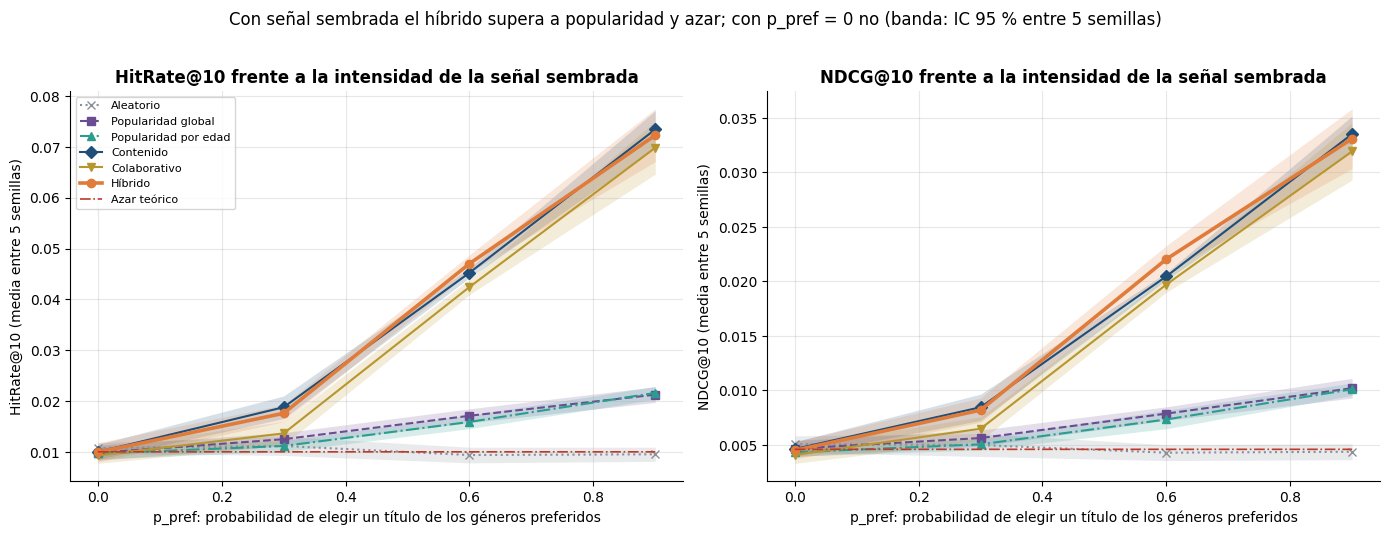

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
estilo = {"Aleatorio": ":", "Popularidad global": "--", "Popularidad por edad": "-.",
          "Contenido": "-", "Colaborativo": "-", "Híbrido": "-"}
marcas = {"Aleatorio": "x", "Popularidad global": "s", "Popularidad por edad": "^",
          "Contenido": "D", "Colaborativo": "v", "Híbrido": "o"}
for ax, met, titulo in ((axes[0], "hit", "HitRate@10"), (axes[1], "ndcg", "NDCG@10")):
    for n in NOMBRES:
        v = np.array([SENAL[p]["ic"][n][met]["valor"] for p in DOSIS])
        lo = np.array([SENAL[p]["ic"][n][met]["ic95"][0] for p in DOSIS])
        hi = np.array([SENAL[p]["ic"][n][met]["ic95"][1] for p in DOSIS])
        color = plots.PALETA[f"rec_{n}"]
        ax.plot(DOSIS, v, color=color, ls=estilo[n], marker=marcas[n], ms=6,
                lw=2.6 if n == "Híbrido" else 1.5, label=n)
        ax.fill_between(DOSIS, lo, hi, color=color, alpha=0.18, lw=0)
    azar = [SENAL[p]["azar"][met] for p in DOSIS]
    ax.plot(DOSIS, azar, color=plots.PALETA["referencia"], ls="-.", lw=1.2, label="Azar teórico")
    ax.set_xlabel("p_pref: probabilidad de elegir un título de los géneros preferidos")
    ax.set_ylabel(f"{titulo} (media entre {N_SEM} semillas)")
    ax.set_title(f"{titulo} frente a la intensidad de la señal sembrada")
axes[0].legend(fontsize=8)
fig.suptitle(f"Con señal sembrada el híbrido supera a popularidad y azar; con p_pref = 0 no "
             f"(banda: IC 95 % entre {N_SEM} semillas)", y=1.02)
fig.tight_layout()
plots.save_fig(fig, "02_senal_sembrada")
plt.show()

**Conclusión técnica.** Cada dosis se evalúa con 5 semillas (generación y partición); se reporta media ± sd [IC 95 % t entre semillas]. Con `p_pref = 0` el pipeline reproduce los datos reales: HitRate@10 del híbrido 0,0100 ± 0,0015 [0,0082; 0,0119], de la popularidad 0,0099 ± 0,0012 y del azar 0,0109 ± 0,0009; Δ híbrido − popularidad = +0,0001 ± 0,0022 [−0,0026; +0,0029]. Con 0,3, el híbrido sube a 0,0177 ± 0,0013 [0,0160; 0,0193] frente a 0,0126 ± 0,0010 de la popularidad (Δ = +0,0051 ± 0,0020 [+0,0026; +0,0076]; ΔNDCG@10 = +0,0026 ± 0,0013 [+0,0009; +0,0042]) y 0,0113 del azar: **con varias semillas la ventaja sobre la popularidad en 0,3 es detectable en media, pero marginal e inestable por semilla** (McNemar mediana p = 0,013 y máximo 0,066, este último la semilla 42 que antes se reportó sola como «no distinguible»; NDCG, mediana 8e-4 y máximo 0,63). Con 0,6: 0,0470 ± 0,0014 [0,0453; 0,0488] frente a 0,0172 (Δ = +0,0299 ± 0,0012 [+0,0284; +0,0313], p ≤ 3e-31 en todas las semillas) y 0,0095 del azar; con 0,9: 0,0722 ± 0,0042 [0,0671; 0,0774] frente a 0,0213 (Δ = +0,0509 ± 0,0048 [+0,0449; +0,0569], p ≤ 1e-54) y 0,0096 del azar. El umbral de detección está, pues, en torno a 0,3 (marginal) y es inequívoco desde 0,6, con ≈ 10 interacciones por usuario. **El método recupera señal cuando existe: la ausencia de mejora en los datos reales es una propiedad de los datos, no un fallo del método.** Matices: (i) con señal por género, el contenido solo y el híbrido no son distinguibles (0,0189, 0,0452 y 0,0734 frente a 0,0177, 0,0470 y 0,0722 con 0,3, 0,6 y 0,9; IC entre semillas solapados, sin contraste pareado entre ambos); (ii) la curva de validación por α es casi plana y la regla mantuvo α = 0,5 en 17 de las 20 ejecuciones (4 dosis × 5 semillas); las 3 excepciones son con `p_pref` = 0 (α = 1,0 en una semilla, p = 0,015: un falso positivo de la regla, esperable al elegir entre 21 valores) y con 0,9 (α = 0,0 y 0,3 en dos semillas, p = 0,029 y 0,001, hacia contenido, coherente con la señal por género); (iii) la señal es por género, justo lo que codifica el contenido: caso favorable. La popularidad también mejora con la señal (0,0213 con 0,9) porque la preferencia por géneros raros concentra visitas en pocos títulos.

**Implicación de negocio.** Si los usuarios de Nile Prime tuvieran gustos reconocibles, este recomendador los detectaría y mejoraría claramente a «lo más visto»; hoy los datos no los contienen.

## 12. Métricas finales (JSON) y ficha del modelo

El JSON recoge la configuración (K y su justificación, α y definición elegidos en validación,
rejilla, pesos de campos, semilla, versiones), el baseline (popularidad global), las cuatro
métricas del híbrido con IC 95 %, todos los recomendadores, el test pareado, la permutación,
cobertura, diversidad, costo operativo, la señal sembrada por `p_pref` y los tiempos por sección.

In [20]:
def nativo(o):
    """Convierte tipos de numpy a tipos nativos de Python para json."""
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(type(o))


def met4(ic):
    """Las cuatro métricas de un recomendador con su nombre @10."""
    return {"hitrate@10": ic["hit"], "ndcg@10": ic["ndcg"],
            "precision@10": ic["precision"], "recall@10": ic["recall"]}


perm_json = {n: {k_: v for k_, v in p.items() if not k_.startswith("nulo_")}
             for n, p in PERM.items()}
resultado = {
    "modo": MODO,
    "config": {
        "semilla": SEED,
        "K": K,
        "K_justificacion": "Longitud de una fila de carrusel en la pantalla de inicio; decisión "
                           "de producto fijada de antemano, no ajustada con los datos.",
        "alpha_elegido": CFG["alpha"],
        "alpha_rejilla": list(REJILLA),
        "definicion_positivo_elegida": CFG["definicion"],
        "definiciones_comparadas": list(rec.DEFINICIONES),
        "regla_seleccion": "En validación: α = argmax NDCG@10 solo si supera a α = 0,5 con "
                           "Wilcoxon p < 0,05, si no 0,5; definición 'completa' solo si supera "
                           "significativamente a 'cualquiera', si no la más simple.",
        "pesos_campos_contenido": rec.PESOS_CAMPOS,
        "particion": {"usuarios_totales": int(inter["User_ID"].nunique()),
                      "usuarios_evaluados": int(n_el), "min_completas": 3,
                      "retenidos_por_usuario": {"validacion": 1, "test": 1},
                      "filas_train": int(len(part["train"])), "retenido": "aleatorio (sin tiempo)"},
        "n_bootstrap": N_BOOT, "n_permutaciones": N_PERM, "dosis_p_pref": DOSIS,
        "versiones": {"python": sys.version.split()[0], "numpy": np.__version__,
                      "pandas": pd.__version__, "scipy": scipy.__version__,
                      "scikit-learn": sklearn.__version__},
        "nota_metricas": "Con un único ítem retenido, recall@10 = hitrate@10 y "
                         "precision@10 = hitrate@10/10 (no son evidencia independiente).",
    },
    "baseline": {
        "nombre": "Popularidad global",
        "metricas": met4(IC["Popularidad global"]),
        "azar_teorico": AZAR,
    },
    "metricas": met4(IC["Híbrido"]),
    "recomendadores_test": {n: met4(IC[n]) for n in NOMBRES},
    "validacion": {"tablas": SEL["tablas"], "alpha_por_definicion": SEL["alpha_por_definicion"],
                   "p_alpha": SEL["p_alpha"], "dif_definiciones": SEL["dif_definiciones"],
                   "completa_gana_significativamente": SEL["completa_gana_significativamente"]},
    "test_pareado_hibrido_menos": PAR,
    "permutacion": perm_json,
    "cobertura_catalogo": COB,
    "diversidad_intralista": DIV,
    "rango_mediano_retenido": med,
    "costo_operativo": COSTO,
    "correccion_colision_titulos": {
        "descripcion": "Popularidad de los títulos repetidos en los metadatos crudos repartida "
                       "entre las películas que comparten título (peso 1/n); solo afecta a la "
                       "popularidad, no a CF ni a contenido.",
        "titulos": colisionados,
        "interacciones_antes": {t_: int(pop[t_]) for t_ in colisionados},
        "arranque_en_frio_top5_antes": FRIO_ANTES,
        "arranque_en_frio_top5_despues": FRIO_USUARIO,
        "metricas_test_antes_despues": EFECTO_POP,
    },
    "arranque_en_frio": {"usuario_nuevo_top5": FRIO_USUARIO,
                         "item_sin_interacciones_puesto_de_The_Godfather": FRIO_ITEM},
    "vecinos_contenido_godfather_posicion_secuelas": GODFATHER_OK,
    "senal_sembrada": {
        str(p): {"config_validacion": r["config"], "azar": r["azar"],
                 "recomendadores": {n: {"hitrate@10": r["ic"][n]["hit"],
                                        "ndcg@10": r["ic"][n]["ndcg"]} for n in NOMBRES},
                 "hibrido_menos": r["pareados"]}
        for p, r in SENAL.items()
    },
    "senal_sembrada_semillas": {
        "n_semillas": N_SEM, "semillas": [SEED + i for i in range(N_SEM)],
        "nota": "En senal_sembrada, 'valor' es la media entre semillas e 'ic95' el IC 95 % "
                "(t de Student) entre semillas; 'sd' su desviación; el p de hibrido_menos es la "
                "mediana de los p por semilla (p_semillas y p_max los acompañan).",
        "alpha_elegido_por_dosis": {str(p): [c["alpha"] for c in SENAL[p]["configs"]]
                                    for p in DOSIS},
    },
    "validacion_por_alpha": {str(p): VAL_ALPHA[p] for p in DOSIS},
    "tiempos_seccion_s": TIEMPOS,
}
ruta = RAIZ / "reports" / "metrics" / "recomendador.json"
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(resultado, indent=2, ensure_ascii=False, default=nativo),
                encoding="utf-8")
print("Guardado: reports/metrics/recomendador.json")
print(f"Tiempo total de las secciones medidas: {sum(TIEMPOS.values()):.0f} s")
print(TIEMPOS)

Guardado: reports/metrics/recomendador.json
Tiempo total de las secciones medidas: 215 s
{'1_datos': 0.1, '2_particion': 0.1, '3_modelos': 0.0, '4_validacion': 3.1, '5_test': 6.5, '6_pareados': 0.7, '7_permutacion': 2.5, '8_cobertura_diversidad': 0.5, '10_costo': 6.0, '11_senal_sembrada': 195.9}


### Ficha del modelo

| Campo | Contenido |
|---|---|
| **Propósito** | Recomendar top-10 títulos no vistos a cada usuario de Nile Prime, con arranque en frío para usuarios nuevos (popularidad por grupo de edad) y títulos nuevos (contenido). |
| **Modelo** | Híbrido ponderado `α·z(CF ítem-ítem coseno) + (1−α)·z(TF-IDF por campos Overview 0,35 / Genre 0,30 / Director 0,15 / Stars 0,20)`, α = 0,5 y positivo = «cualquier película vista», elegidos en validación (sin diferencia significativa: elección por regla, no por mérito). |
| **Datos** | 999 títulos únicos y 100.623 interacciones de 10.000 usuarios sin marca de tiempo; 9.950 usuarios elegibles (≥ 3 vistas completas) con un ítem retenido aleatorio en validación y otro en test. |
| **Métricas (test, n = 9.950, IC 95 % bootstrap sobre usuarios, 1.000 remuestreos)** | HitRate@10 = 0,0110 [0,0089; 0,0130]; NDCG@10 = 0,0056 [0,0044; 0,0068]; Precision@10 = 0,0011 [0,0009; 0,0013]; Recall@10 = 0,0110 [0,0089; 0,0130] (los dos últimos, reescalados de HitRate@10). Azar teórico: 0,0101 y 0,0046. Baseline popularidad global (corregida por colisión de títulos): 0,0099 y 0,0046. |
| **Significancia** | Híbrido − popularidad global: ΔHitRate@10 = +0,0010 [−0,0019; +0,0039] (p = 0,53), ΔNDCG@10 = +0,0010 [−0,0005; +0,0026] (p = 0,23): sin diferencia. Frente a popularidad por edad, ΔNDCG@10 = +0,0018 con p = 0,023 nominal (1 de 6 contrastes; ese baseline queda bajo el azar). Permutación (1.000 réplicas): sin señal en HitRate@10 (p = 0,12-0,89); NDCG@10 del híbrido p = 0,021 nominal (no resiste corrección múltiple). |
| **Señal sembrada** | 5 semillas por dosis (media ± sd; IC 95 % entre semillas). `p_pref` = 0 → azar; 0,3 → HitRate@10 = 0,0177 ± 0,0013 frente a 0,0126 de la popularidad (Δ = +0,0051 [+0,0026; +0,0076]; ventaja marginal, p por semilla hasta 0,066); 0,6 → 0,0470 ± 0,0014 frente a 0,0172; 0,9 → 0,0722 ± 0,0042 frente a 0,0213. |
| **Costo** | Ajuste < 0,1 s; ≈ 3 ms por recomendación individual y 0,06 ms por usuario en lote; 18,4 MB en memoria. |
| **Limitaciones y riesgos** | Sin señal de preferencias en el histórico (rendimiento ≈ azar); retenido aleatorio sin marca de tiempo (no se evalúa predicción temporal y el modelo ve «el futuro» del usuario); «Drishyam» fusiona dos películas en `interacciones.csv` (solo trae el título): se corrige repartiendo su popularidad entre ambas (peso 1/2), pero CF y contenido siguen tratándolas como un único ítem (la fila de mayor `No_of_Votes`); sesgo de popularidad en CF y popularidad; señal sintética por género, favorable al contenido; sin evaluación en línea (no se mide aceptación real ni efecto sobre el visionado); IC bootstrap que ignora la variabilidad de la partición aleatoria; Precision y Recall no independientes. |
| **Uso previsto / no previsto** | Previsto: motor de candidatos y arranque en frío por contenido y popularidad, a validar en línea. No previsto: afirmar mejora de personalización con este histórico. |
| **Conexión con el reto 4** | Sin señal en el histórico, las preferencias no pueden aprenderse offline; solo la interacción en línea (aprendizaje por refuerzo / *bandits*, reto 4 sobre `agent.py`) permite descubrirlas explorando y observando la respuesta de cada usuario. |